### Read the vcf file and process it

In [26]:
import pandas as pd
import random
import numpy as np

vcf = pd.read_csv("initial_population.vcf", sep="\t")
vcf = vcf.drop(columns=["#CHROM", "POS", "ID", "REF", "ALT", "QUAL"])
vcf = vcf.T
vcf = vcf.values.tolist()
vcf = [[list(map(int, elem.split('|'))) for elem in row] for row in vcf]

In [2]:
N = len(vcf)
print("Number of Individuals in the Initial Population:", N)

Number of Individuals in the Initial Population: 100


In [3]:
N_SNPs = len(vcf[0])
print("Number of SNPs:", N_SNPs)

Number of SNPs: 10000


Below is just some sanity check of the data

In [4]:
def snp_count(snp, pos):
    # pos = 0 is maternal
    # pos = 1 is paternal
    count_1 = [row[pos] for row in snp].count(1)
    return count_1



for n in range(N_SNPs):
    snp = [row[n] for row in vcf]
    maternal_count = snp_count(snp, 0)
    paternal_count = snp_count(snp, 1)

    assert maternal_count <= 1
    assert paternal_count <= 1
    assert maternal_count == 1 or paternal_count == 1
    assert not (maternal_count == 1 and paternal_count == 1)

### Main code

In [5]:
def reproduce(p1, p2):
    # assume
    # p1 is mother
    #   [0] is maternal chrom. a0...aL-1
    #   [1] is paternal chrom. b0...bL-1
    # p2 is father
    #   [0] is maternal chrom. c0...cL-1
    #   [1] is paternal chrom. d0...dL-1

    # find crossover position k and k' (uniformly among {0, 1, …, L-1})
    k = random.randint(0, N_SNPs + 1)
    k_prime = random.randint(0, N_SNPs + 1)

    order = random.randint(0, 1)
    # TODO: Ask about when k == 0, also should k be random.randint(0, N_SNPs) instead?
    if order == 0:
        # a0...ak bk+1...bL-1
        maternal_chromosome = [SNP[0] for SNP in p1[:k]] + [SNP[1] for SNP in p1[k:]]
    else:
        # b0...bk ak+1...aL-1
        maternal_chromosome = [SNP[1] for SNP in p1[:k]] + [SNP[0] for SNP in p1[k:]]

    order = random.randint(0, 1)
    if order == 0:
        # c0...ck’ dk’+1...dL-1
        paternal_chromosome = [SNP[0] for SNP in p2[:k_prime]] + [
            SNP[1] for SNP in p2[k_prime:]
        ]
    else:
        # d0...dk’ ck’+1...cL-1
        paternal_chromosome = [SNP[1] for SNP in p2[:k_prime]] + [
            SNP[0] for SNP in p2[k_prime:]
        ]

    child = [[a, b] for a, b in zip(maternal_chromosome, paternal_chromosome)]

    return child

In [36]:
def simulate(population):
    children = []

    for _ in range(N):
        # Pick parent P1 based on fitness wrt population PopG

        # in the case of all neutral alleles:
        p1_index = random.randint(0, N - 1)
        p1 = population[p1_index]

        # Pick parent P2≠P1 based on fitness wrt population PopG

        # in the case of all neutral alleles:
        p2_index = random.randint(0, N - 1)
        while p1_index == p2_index:
            p2_index = random.randint(0, N - 1)
        p2 = population[p2_index]

        assert p1_index != p2_index

        children.append(reproduce(p1, p2))

    return children

In [8]:
def run_simulation(initial_population = vcf, gens_to_simulate = 1):
    generations = []
    for _ in range(gens_to_simulate):
        generations.append(simulate(population=initial_population))
        initial_population = generations[-1]
    return generations

### Experiments

c) (2 points) Use your simulation code to estimate the probability of the event described in (b), still under the assumption that all alleles are selectively neutral. This is simply done by seeing what fraction of the 10,000 SNPs went to extinction in generation 1. Does it approximately match your result in (b)?

In [9]:
# We're going to run the experiment multiple times (e) and calculate the answer as an ensemble across multiple simulations
e = 100
percentage_trues = []
for _ in range(e):
    generations = run_simulation(vcf, 1)
    gen1 = generations[0]

    alt_exists = []
    for n in range(N_SNPs):
        snp = [row[n] for row in gen1]

        assert all(sublist != [1, 1] for sublist in snp), "Found [1, 1], which is not possible!"

        maternal_count = snp_count(snp, 0)
        paternal_count = snp_count(snp, 1)

        alt_count = maternal_count + paternal_count
        alt_exists.append(alt_count != 0)

    num_trues = alt_exists.count(False)

    # Calculate the percentage of True values
    percentage_trues.append((num_trues / len(alt_exists)) * 100)


print(f"Probability that an alternate allele becomes extinct after 1 generation: {sum(percentage_trues)/len(percentage_trues)}%")

Probability that an alternate allele becomes extinct after 1 generation: 36.45350000000001%


d) (2 points) Starting from the same initial population, simulate the evolution of a population over 20 generations, still assuming that all alleles are selectively neutral. Plot the alternate allele frequency of the first 100 SNPs. The figure on the right is what I get; your result may differ, since this is a random process.

In [9]:
generations = run_simulation(vcf, gens_to_simulate=20)

In [10]:
frequencies_acc_generations = []
for generation in generations:  # loop across generations:
    frequencies = []
    for n in range(100):  # only plotting first 100 SNPs
        snp = [row[n] for row in generation]

        maternal_count = snp_count(snp, 0)
        paternal_count = snp_count(snp, 1)

        alt_count = maternal_count + paternal_count
        frequencies.append(alt_count / (2 * N))
    frequencies_acc_generations.append(frequencies)

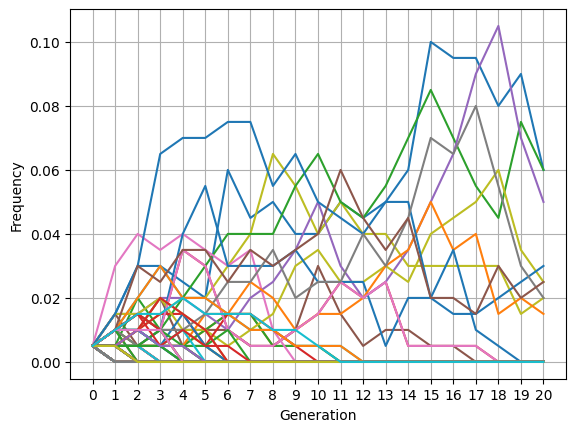

In [11]:
import matplotlib.pyplot as plt 

plt.figure()
for n in range(100):
    freqs = [1/200] + [row[n] for row in frequencies_acc_generations]
    plt.plot(list(range(len(generations) + 1)), freqs, label=f"SNP {n}")
# plt.legend()
plt.grid()
plt.xticks(list(range(21)))
plt.xlabel("Generation")
plt.ylabel("Frequency")
plt.show()

e) (5 points) Repeat the simulation, this time going for 1000 generations. Plot (i) the
probability of allele extinction as a function of generation; (ii) the probability of allele
fixation as a function of generation. These probabilities can be estimated by simply
observing what fraction of the 10000 SNPs go to extinction or fixation.

In [12]:
probability_fixation_generations = []
probability_extinction_generations = []

# TODO: Does extinction mean heterozygous too? Or Homozygous for alt allele? Ask
initial_population = vcf
for _ in range(1000):
    latest_generation = simulate(population=initial_population)
    initial_population = latest_generation

    is_fixated = []
    is_extinct = []
    for n in range(N_SNPs):
        snp = [row[n] for row in latest_generation]

        maternal_count = snp_count(snp, 0)
        paternal_count = snp_count(snp, 1)

        alt_count = maternal_count + paternal_count
        is_fixated.append(alt_count == (2 * N))
        is_extinct.append(alt_count == 0)
    
    assert len(is_fixated) == N_SNPs
    assert len(is_extinct) == N_SNPs

    probability_fixation_generations.append(sum(is_fixated)/N_SNPs)
    probability_extinction_generations.append(sum(is_extinct)/N_SNPs)

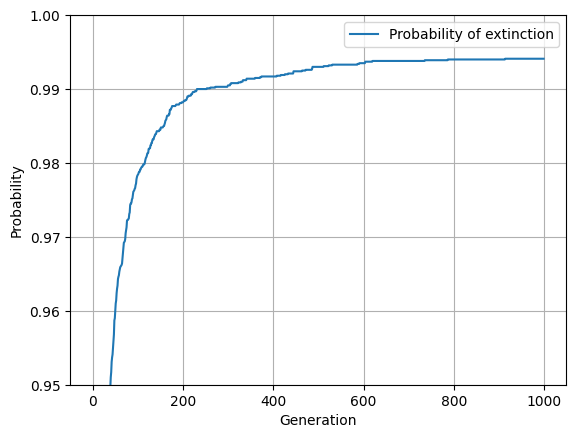

In [17]:
plt.figure()
plt.plot(list(range((len(probability_extinction_generations)))), probability_extinction_generations, label="Probability of extinction")
plt.legend()
plt.grid()
plt.ylim(0.95, 1)
plt.xlabel("Generation")
plt.ylabel("Probability")
plt.show()

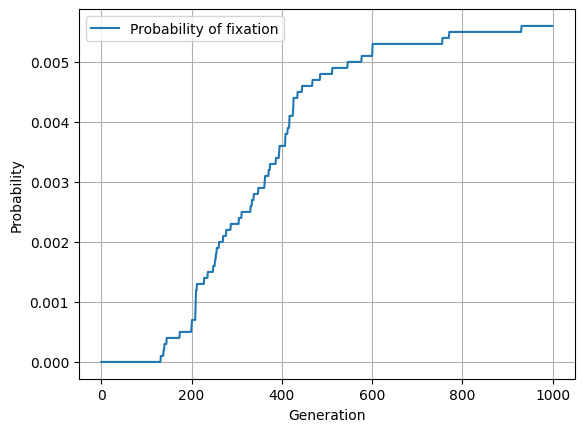

In [18]:
plt.figure()
plt.plot(list(range(len(probability_fixation_generations))), probability_fixation_generations, label="Probability of fixation")
plt.legend()
plt.grid()
plt.xlabel("Generation")
plt.ylabel("Probability")
plt.show()

In [19]:
print(f"Probability of fixation converges to {probability_fixation_generations[-1]}")
print(f"Probability of extinction converges to {probability_extinction_generations[-1]}")

Probability of fixation converges to 0.0056
Probability of extinction converges to 0.9941


f) (2 points) Now, assume that there is one speciﬁc SNPs (say SNP42) where being
heterozygous confers a fitness of 1.5 (compared to a fitness of 1 for other alleles) and
being homozygous for the alternate allele confers a fitness of 2. This means that an
individual who is heterozygous at SNP42 is 50% more likely to be selected as a parent in
the simulation, while an individual who is homozygous for the alternate allele at SNP42
is twice as likely to be selected. Calculate analytically the probability of extinction of the
alternate allele at SNP42 after one generaAon. Use your simulation code to confirm your
calculation, by running your 1-generaAon simulation repeatedly.

In [13]:
# Adjust the simulate function to consider the new fitness scoring
def simulate(population):
    children = []

    for _ in range(N):
        # Pick parent P1 based on fitness wrt population PopG
    
        fitnesses = []
        for individual in vcf:
            if individual[42] == [0, 0]:
                fitnesses.append(1)
            elif individual[42] == [1, 1]:
                fitnesses.append(2)
            else: 
                fitnesses.append(1.5)


        total_fitness = sum(fitnesses)
        probabilities = [fitness / total_fitness for fitness in fitnesses]

        p1_index = random.choices(range(len(fitnesses)), weights=probabilities)[0]
        p1 = population[p1_index]

        # Pick parent P2≠P1 based on fitness wrt population PopG

        # in the case of all neutral alleles:
        p2_index = random.choices(range(len(fitnesses)), weights=probabilities)[0]
        while p1_index == p2_index:
            p2_index = random.choices(range(len(fitnesses)), weights=probabilities)[0]
        p2 = population[p2_index]
        
        assert p1_index != p2_index

        children.append(reproduce(p1, p2))

    return children

In [36]:
# We're going to run the experiment multiple times (e) and calculate the answer as an ensemble across multiple simulations
e = 1000
is_extinct = []
for _ in range(e):
    generations = run_simulation(vcf, 1)
    gen1 = generations[0]

    alt_exists = []
    snp = [row[42] for row in gen1]

    assert all(sublist != [1, 1] for sublist in snp), "Found [1, 1], which is not possible!"

    maternal_count = snp_count(snp, 0)
    paternal_count = snp_count(snp, 1)

    alt_count = maternal_count + paternal_count
    is_extinct.append(alt_count == 0)

print(f"Probability that the alternate allele at SNP42 becomes extinct after 1 generation: {sum(is_extinct)/len(is_extinct)}%")

Probability that the alternate allele at SNP42 becomes extinct after 1 generation: 0.224%


g) (2 points) Under the setting described in (f), use your simulation to estimate the
probabilities of extinction and fixation of the alternate allele at SNP42, after 100 (not
1000) generations. To estimate these probabilities, you will need to run your simulation
multiple times (I recommend 1000 times). Since the answer does not depend on the
SNPs other than SNP 42, your simulation can involve only that SNP, which will make
things faster.

In [27]:
# Adjust the simulate function to consider the new fitness scoring
def simulate(population):
    children = []

    for _ in range(N):
        # Pick parent P1 based on fitness wrt population PopG
    
        fitnesses = []
        for individual in vcf:
            if individual[2] == [0, 0]:
                fitnesses.append(1)
            elif individual[2] == [1, 1]:
                fitnesses.append(2)
            else: 
                fitnesses.append(1.5)


        total_fitness = sum(fitnesses)
        probabilities = [fitness / total_fitness for fitness in fitnesses]

        p1_index = random.choices(range(len(fitnesses)), weights=probabilities)[0]
        p1 = population[p1_index]

        # Pick parent P2≠P1 based on fitness wrt population PopG

        # in the case of all neutral alleles:
        p2_index = random.choices(range(len(fitnesses)), weights=probabilities)[0]
        while p1_index == p2_index:
            p2_index = random.choices(range(len(fitnesses)), weights=probabilities)[0]
        p2 = population[p2_index]
        
        assert p1_index != p2_index

        children.append(reproduce(p1, p2))

    return children

In [28]:
vcf_small = [person[40:45] for person in vcf]
vcf_backup = vcf 

In [29]:
vcf = vcf_small
len(vcf[0])

5

In [30]:
# We're going to run the experiment multiple times (e) and calculate the answer as an ensemble across multiple simulations
e = 1000
is_fixated, is_extinct = [], []
for _ in range(e):
    generations = run_simulation(vcf, 100)
    last_gen = generations[-1]

    snp = [row[2] for row in last_gen]

    maternal_count = snp_count(snp, 0)
    paternal_count = snp_count(snp, 1)

    alt_count = maternal_count + paternal_count
    is_fixated.append(alt_count == (2 * N))
    is_extinct.append(alt_count == 0)


print("Probability of fixation:", sum(is_fixated)/len(is_fixated))
print("Probability of extinction:", sum(is_extinct)/len(is_extinct))

Probability of fixation: 0.001
Probability of extinction: 0.971


In [31]:
# We're going to run the experiment multiple times (e) and calculate the answer as an ensemble across multiple simulations
e = 1000
num_fixated, num_extinct = [], []
for _ in range(e):
    generations = run_simulation(vcf, 100)
    last_gen = generations[-1]

    snp = [row[2] for row in last_gen]
    num_extinct.append(snp.count([0, 0]))
    num_fixated.append(snp.count([1, 1]))

print("Probability of extinction:", sum(num_extinct)/(1000*100)) 
print("Probability of fixation:", sum(num_fixated)/(1000*100)) 

Probability of extinction: 0.9864
Probability of fixation: 0.00309


(2 points) Now assume that the alternate allele at SNP42 is instead deleterious (it
reduces fitness). Being heterozygous at SNP42 yields a fitness of 0.9, and being
homozygous yields a fitness of 0.8. Use your simulation to estimate the probability of
extinction and fixation after 100 (not 1000) generations. To estimate these probabilities,
you will need to run your simulation multiple times (I recommend 1000 times). Since the
answer does not depend on the SNPs other than SNP 42, your simulation can involve
only that SNP, which will make things faster.

In [32]:
# Adjust the simulate function to consider the new fitness scoring
def simulate(population):
    children = []

    for _ in range(N):
        # Pick parent P1 based on fitness wrt population PopG
    
        fitnesses = []
        for individual in vcf:
            if individual[2] == [0, 0]:
                fitnesses.append(1)
            elif individual[2] == [1, 1]:
                fitnesses.append(0.8)
            else: 
                fitnesses.append(0.9)


        total_fitness = sum(fitnesses)
        probabilities = [fitness / total_fitness for fitness in fitnesses]

        p1_index = random.choices(range(len(fitnesses)), weights=probabilities)[0]
        p1 = population[p1_index]

        # Pick parent P2≠P1 based on fitness wrt population PopG

        # in the case of all neutral alleles:
        p2_index = random.choices(range(len(fitnesses)), weights=probabilities)[0]
        while p1_index == p2_index:
            p2_index = random.choices(range(len(fitnesses)), weights=probabilities)[0]
        p2 = population[p2_index]
        
        assert p1_index != p2_index

        children.append(reproduce(p1, p2))

    return children

In [33]:
# We're going to run the experiment multiple times (e) and calculate the answer as an ensemble across multiple simulations
e = 1000
num_fixated, num_extinct = [], []
for _ in range(e):
    generations = run_simulation(vcf, 100)
    last_gen = generations[-1]

    snp = [row[2] for row in last_gen]
    num_extinct.append(snp.count([0, 0]))
    num_fixated.append(snp.count([1, 1]))

print("Probability of extinction:", sum(num_extinct)/(1000*100)) 
print("Probability of fixation:", sum(num_fixated)/(1000*100)) 

Probability of extinction: 0.99275
Probability of fixation: 0.0014


In [34]:
# We're going to run the experiment multiple times (e) and calculate the answer as an ensemble across multiple simulations
e = 1000
is_fixated, is_extinct = [], []
for _ in range(e):
    generations = run_simulation(vcf, 100)
    last_gen = generations[-1]

    snp = [row[2] for row in last_gen]

    maternal_count = snp_count(snp, 0)
    paternal_count = snp_count(snp, 1)

    alt_count = maternal_count + paternal_count
    is_fixated.append(alt_count == (2 * N))
    is_extinct.append(alt_count == 0)


print("Probability of fixation:", sum(is_fixated)/len(is_fixated))
print("Probability of extinction:", sum(is_extinct)/len(is_extinct))

Probability of fixation: 0.0
Probability of extinction: 0.975


In [37]:
# normal 

# We're going to run the experiment multiple times (e) and calculate the answer as an ensemble across multiple simulations
e = 1000
num_fixated, num_extinct = [], []
for _ in range(e):
    generations = run_simulation(vcf, 100)
    last_gen = generations[-1]

    snp = [row[2] for row in last_gen]
    num_extinct.append(snp.count([0, 0]))
    num_fixated.append(snp.count([1, 1]))

print("Probability of extinction:", sum(num_extinct)/(1000*100)) 
print("Probability of fixation:", sum(num_fixated)/(1000*100)) 

Probability of extinction: 0.98981
Probability of fixation: 0.00246
